# Projet : Analyse de sentiments — PHASE 2 : modélisation
**Entrées :** `data/processed/train.csv`, `test.csv`, `graph_nodes.csv`, `graph_adj.npz` (produits par la phase 1).
**Sorties :** `plots/09_` à `12_`, `data/processed/resultats_phase2.json`.
Contenu : baselines (hasard, SVM, régression logistique), polarité, matrice de confusion, validation croisée,
classification de nœuds (texte contre graphe), mots influents, explication locale (LIME).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

try:                              # exécution comme script : code/phase2_modeling.py
    BASE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
except NameError:                 # exécution dans un notebook placé dans code/
    BASE = os.path.abspath("..")
PROC = os.path.join(BASE, "data", "processed"); PLOTS = os.path.join(BASE, "plots")
os.makedirs(PLOTS, exist_ok=True)
SEED = 42; R = {}
def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(PLOTS, name), dpi=130); plt.show()

## 1. Données et représentation TF-IDF (identiques à la phase 1)

In [2]:
train = pd.read_csv(os.path.join(PROC, "train.csv")); test = pd.read_csv(os.path.join(PROC, "test.csv"))
ytr, yte = train.emotion, test.emotion
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = tfidf.fit_transform(train.clean); X_test = tfidf.transform(test.clean)
labels = sorted(train.emotion.unique())
print(X_train.shape, X_test.shape)

(63652, 63549) (15913, 63549)


## 2. Baselines : hasard, SVM linéaire, régression logistique (11 émotions)

In [3]:
def scores(y, p): return {"accuracy": round(accuracy_score(y, p), 4), "f1_macro": round(f1_score(y, p, average="macro"), 4)}
dummy = DummyClassifier(strategy="stratified", random_state=SEED).fit(X_train, ytr)
R["hasard"] = scores(yte, dummy.predict(X_test))
svm = LinearSVC(C=0.5).fit(X_train, ytr); p_svm = svm.predict(X_test); R["svm"] = scores(yte, p_svm)
lr = LogisticRegression(C=10, max_iter=100).fit(X_train, ytr); R["logreg"] = scores(yte, lr.predict(X_test))
rep = classification_report(yte, p_svm, output_dict=True, zero_division=0)
R["par_emotion"] = {e: {**{k: round(rep[e][k], 3) for k in ("precision", "recall", "f1-score")}, "support": int(rep[e]["support"])} for e in labels}
print(R["hasard"], R["svm"], R["logreg"])

{'accuracy': 0.0934, 'f1_macro': 0.0876} {'accuracy': 0.8082, 'f1_macro': 0.8144} {'accuracy': 0.7963, 'f1_macro': 0.8026}


## 3. Polarité (3 classes)

In [4]:
POL = {"happiness": "positive", "fun": "positive", "enthusiasm": "positive", "love": "positive", "relief": "positive",
       "sadness": "negative", "anger": "negative", "hate": "negative", "neutral": "neutral", "surprise": "neutral", "empty": "neutral"}
svm_p = LinearSVC(C=0.5).fit(X_train, ytr.map(POL)); p_pol = svm_p.predict(X_test)
R["polarite"] = scores(yte.map(POL), p_pol)
R["polarite_majoritaire"] = round(float(yte.map(POL).value_counts(normalize=True).max()), 3)
R["polarite_par_classe"] = {k: {m: round(v[m], 3) for m in ("precision", "recall", "f1-score")}
                            for k, v in classification_report(yte.map(POL), p_pol, output_dict=True).items() if k in ("negative", "neutral", "positive")}
print(R["polarite"], R["polarite_majoritaire"])

{'accuracy': 0.8472, 'f1_macro': 0.8382} 0.453


## 4. Matrice de confusion et principales confusions

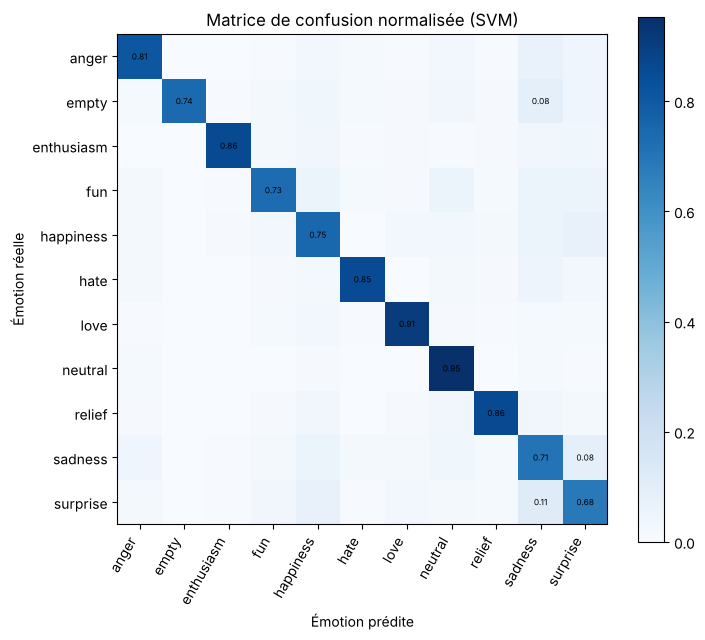

[('surprise', 'sadness', 0.114), ('empty', 'sadness', 0.084), ('sadness', 'surprise', 0.082), ('surprise', 'happiness', 0.073), ('happiness', 'surprise', 0.071), ('anger', 'sadness', 0.066)]


In [5]:
cm = confusion_matrix(yte, p_svm, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues"); ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right"); ax.set_yticklabels(labels)
ax.set_xlabel("Émotion prédite"); ax.set_ylabel("Émotion réelle")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] > .08: ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=6)
ax.set_title("Matrice de confusion normalisée (SVM)"); plt.colorbar(im)
save_fig("09_matrice_confusion.png")
off = [(labels[i], labels[j], cm[i, j]) for i in range(len(labels)) for j in range(len(labels)) if i != j]
R["confusions"] = [(a, b, round(float(v), 3)) for a, b, v in sorted(off, key=lambda x: -x[2])[:6]]
print(R["confusions"])

## 5. Validation croisée à 5 plis (sur le jeu d'entraînement seulement)

In [6]:
pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True), LinearSVC(C=0.5))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cvs = cross_val_score(pipe, train.clean, train.emotion, cv=cv, scoring="f1_macro")
R["cv_f1_plis"] = [round(float(s), 4) for s in cvs]; R["cv_f1_moyenne"] = round(float(cvs.mean()), 4); R["cv_f1_ecart_type"] = round(float(cvs.std()), 4)
print(R["cv_f1_plis"], R["cv_f1_moyenne"], R["cv_f1_ecart_type"])

[0.8144, 0.8117, 0.8126, 0.8203, 0.8127] 0.8143 0.0031


## 6. Classification de nœuds : texte seul contre graphe
Représentations : texte (TF-IDF), voisinage à 1 saut (Â·X), à 2 sauts (Â²·X, type SGC), texte + voisinage.

             representation  accuracy  f1_macro
   Texte seul (TF-IDF + LR)    0.7022    0.7108
        Graphe 1 saut (Â·X)    0.6067    0.6171
  Graphe 2 sauts SGC (Â²·X)    0.5739    0.5802
Texte + voisinage (concat.)    0.7067    0.7131


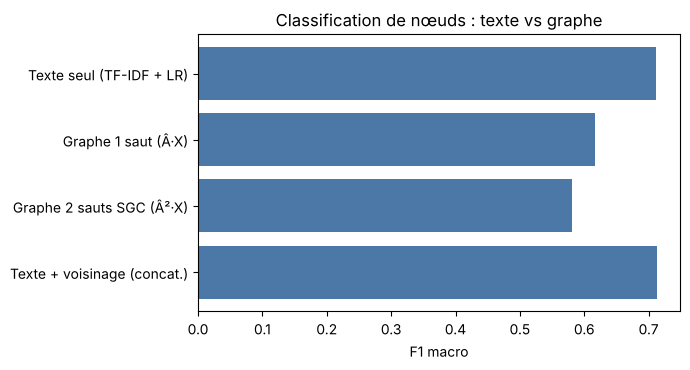

In [7]:
gs = pd.read_csv(os.path.join(PROC, "graph_nodes.csv")); Sg = sp.load_npz(os.path.join(PROC, "graph_adj.npz")).tocsr(); N = len(gs)
idx = np.arange(N)
itr, ite = train_test_split(idx, test_size=0.3, stratify=gs.emotion, random_state=SEED)
y = gs.emotion.values
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(gs.clean.iloc[itr])
Xg = vec.transform(gs.clean)
A_ = Sg.copy(); A_.data[:] = 1; A_ = A_ + sp.eye(N)                       # graphe non pondéré avec auto-boucles
dg = np.asarray(A_.sum(1)).ravel(); Dm = sp.diags(1 / np.sqrt(dg))
Ahat = (Dm @ A_ @ Dm).tocsr()                                              # Â = D^-1/2 (A + I) D^-1/2
X1 = (Ahat @ Xg).tocsr(); X2 = (Ahat @ X1).tocsr()
def ev(X, name):
    m = LogisticRegression(C=10, max_iter=300).fit(X[itr], y[itr]); q = m.predict(X[ite])
    return {"representation": name, **scores(y[ite], q)}
res = [ev(Xg, "Texte seul (TF-IDF + LR)"), ev(X1, "Graphe 1 saut (Â·X)"), ev(X2, "Graphe 2 sauts SGC (Â²·X)"),
       ev(sp.hstack([Xg, X1]).tocsr(), "Texte + voisinage (concat.)")]
R["noeuds"] = res; R["noeuds_split"] = [len(itr), len(ite)]
print(pd.DataFrame(res).to_string(index=False))
plt.figure(figsize=(7, 3.8))
plt.barh([r["representation"] for r in res][::-1], [r["f1_macro"] for r in res][::-1], color="#4C78A8")
plt.xlabel("F1 macro"); plt.title("Classification de nœuds : texte vs graphe")
save_fig("10_noeuds_texte_vs_graphe.png")

## 7. Explication : mots les plus influents par émotion (régression logistique)

In [8]:
names = np.array(tfidf.get_feature_names_out())
R["mots_influents"] = {e: [str(w) for w in names[np.argsort(-lr.coef_[i])[:8]]] for i, e in enumerate(lr.classes_)}
for e, w in R["mots_influents"].items(): print(f"{e:<11}:", ", ".join(w))

anger      : angry, discouraged, outraged, enraged, average, encourage, encouraged, rage
empty      : empty, avoid, avoiding, avoided, void, hollow, to avoid, feel empty
enthusiasm : excited, eager, eager to, enthusiastic, and excited, eagerly, feel excited, excited and
fun        : funny, joyful, fun, function, funk, funeral, amusing, functional
happiness  : happy, unhappy, content, enjoy, discontent, contented, joy, enjoyed
hate       : hated, hate, whatever, hateful, hate feeling, hates, loathe, detest
love       : love, loved, beloved, lovely, affectionate, unloved, loves, affection
neutral    : feel, feeling, feels, feelings, strange, rotten, disgusted, worthwhile
relief     : uncomfortable, comfortable, pleased, comfort, please, relief, ease, discomfort
sadness    : sad, depressed, melancholy, anxiety, sadness, concerned, worry, worrying
surprise   : surprised, shocked, surprise, shock, surprises, shocking, sad, astonishment


## 8. Explication locale (LIME) — nécessite `pip install lime`

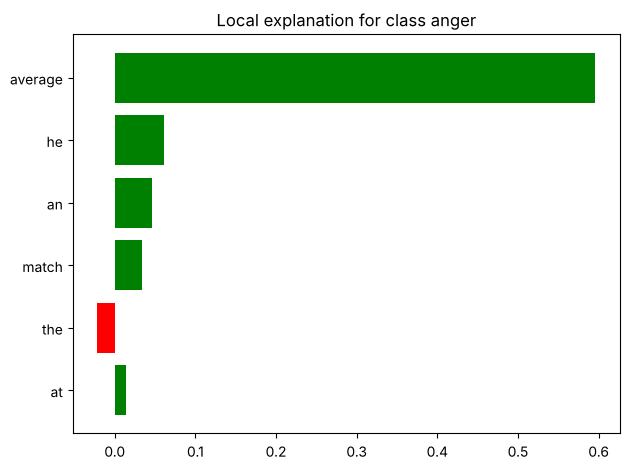

he gave an average performance at the match -> {'classe': 'anger', 'poids': [('average', 0.596), ('he', 0.061), ('an', 0.047), ('match', 0.034), ('the', -0.021), ('at', 0.014)]}


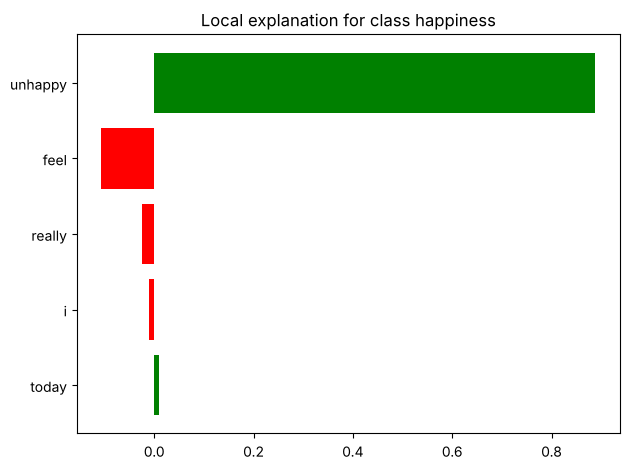

i feel really unhappy today -> {'classe': 'happiness', 'poids': [('unhappy', 0.888), ('feel', -0.106), ('really', -0.024), ('i', -0.011), ('today', 0.009)]}


In [9]:
try:
    from lime.lime_text import LimeTextExplainer
    explainer = LimeTextExplainer(class_names=list(lr.classes_), random_state=SEED)
    predict_fn = lambda texts: lr.predict_proba(tfidf.transform(texts))
    R["lime"] = {}
    for texte, fname in [("he gave an average performance at the match", "11_lime_average.png"),
                         ("i feel really unhappy today", "12_lime_unhappy.png")]:
        exp = explainer.explain_instance(texte, predict_fn, num_features=6, top_labels=1)
        lab = exp.available_labels()[0]
        R["lime"][texte] = {"classe": str(lr.classes_[lab]), "poids": [(str(m), round(float(v), 3)) for m, v in exp.as_list(label=lab)]}
        exp.as_pyplot_figure(label=lab); save_fig(fname)
        print(texte, "->", R["lime"][texte])
except ImportError:
    print("LIME non installé : pip install lime")

In [10]:
json.dump(R, open(os.path.join(PROC, "resultats_phase2.json"), "w"), indent=1, ensure_ascii=False, default=str)
print("Phase 2 terminée.")

Phase 2 terminée.
